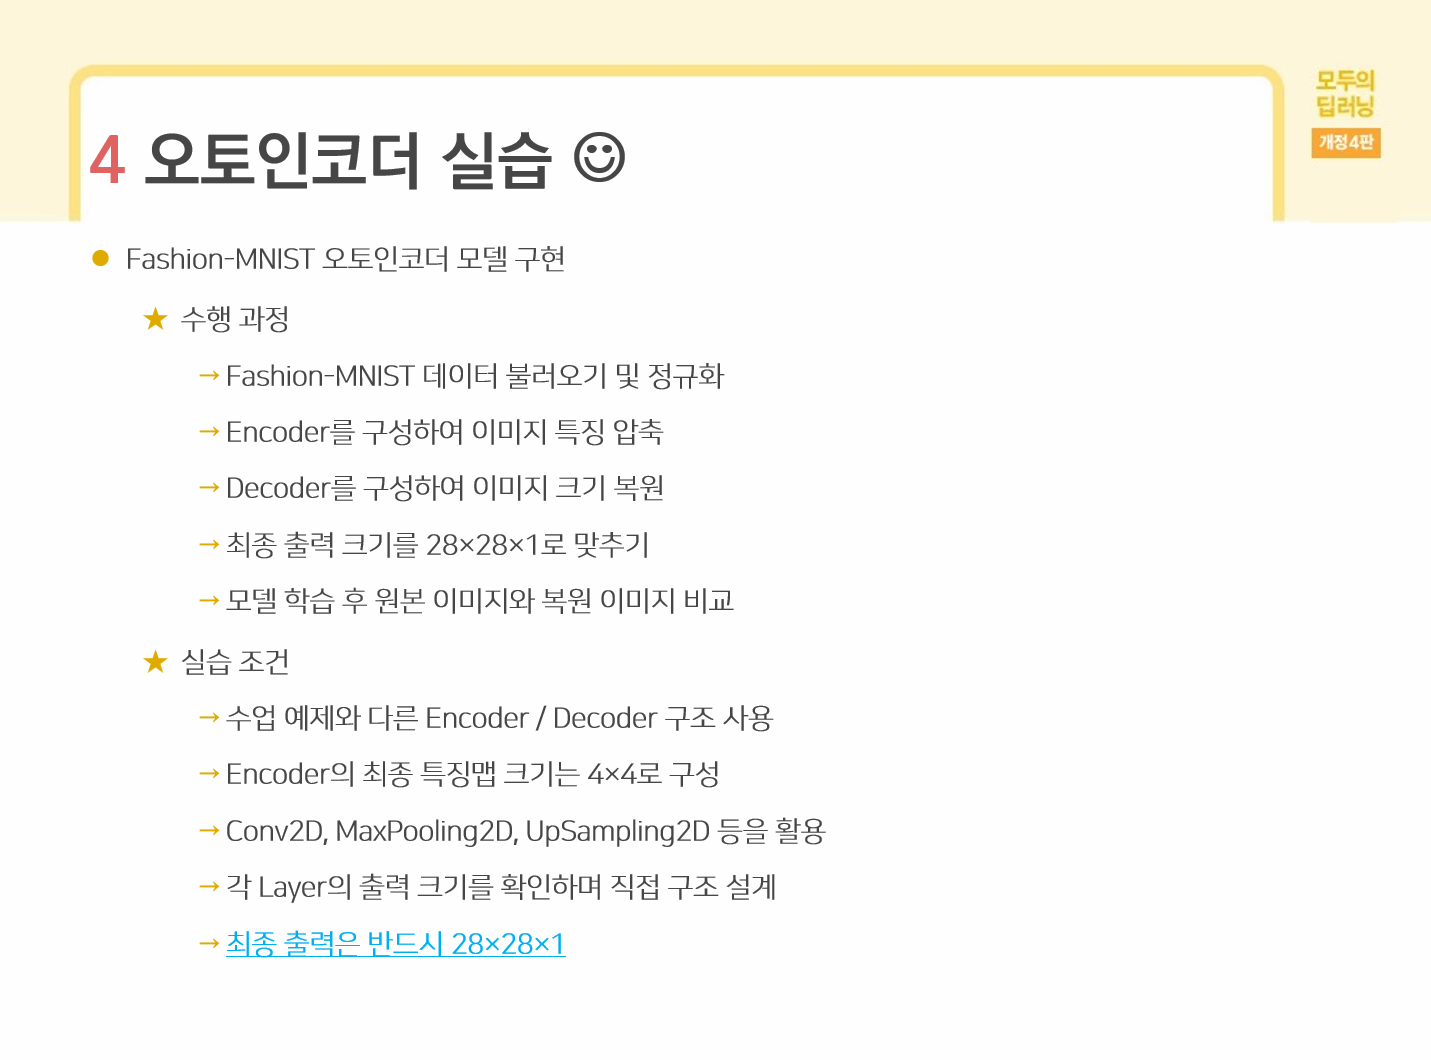

In [ ]:
# 필요한 라이브러리 불러오기
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPooling2D, UpSampling2D, Flatten, Reshape,BatchNormalization

import matplotlib.pyplot as plt
import numpy as np

# 1. MNIST 데이터셋 로드 (라벨은 사용하지 않으므로 _로 처리)
(X_train, _), (X_test, _) = fashion_mnist.load_data()

# 2. 데이터 전처리: (개수, 28, 28, 1) 형태로 차원 변경 및 0~1 사이로 정규화
# 데이터 형태: (60000, 28, 28, 1)
X_train = X_train.reshape(X_train.shape[0], 28, 28, 1).astype('float32') / 255
X_test = X_test.reshape(X_test.shape[0], 28, 28, 1).astype('float32') / 255

autoencoder = Sequential()

# 입력 크기: (28, 28, 1)

# [층 1] Conv2D: 16개 필터, 3x3 커널, padding='same'
# 출력 크기: (28, 28, 16) <- 질문하신 대로 28x28x16이 됩니다!
autoencoder.add(Conv2D(16, kernel_size=3, padding='same', input_shape=(28,28,1), activation='relu'))
autoencoder.add(BatchNormalization())

# 출력 크기: (14, 14, 16)
autoencoder.add(MaxPooling2D(pool_size=2, padding='same'))

# 출력 크기: (14, 14, 8)
autoencoder.add(Conv2D(8, kernel_size=3, activation='relu', padding='same'))
autoencoder.add(BatchNormalization())

# 출력 크기: (7, 7, 8)
autoencoder.add(MaxPooling2D(pool_size=2, padding='same'))


# 출력 크기: (4, 4, 8)
autoencoder.add(Conv2D(8, kernel_size=3, strides=2, padding='same', activation='relu'))
autoencoder.add(BatchNormalization())

# ==================== [ 디코더 (Decoder) ] ====================
# 입력 크기: (4, 4, 8)

# [층 6] Conv2D: 8개 필터, 3x3 커널, padding='same'
# 출력 크기: (4, 4, 8)
autoencoder.add(Conv2D(8, kernel_size=3, padding='same', activation='relu'))
autoencoder.add(BatchNormalization())
# [층 7] UpSampling2D: 가로, 세로 2배 확대
# 출력 크기: (8, 8, 8)
autoencoder.add(UpSampling2D())

# [층 8] Conv2D: 8개 필터, 3x3 커널, padding='same'
# 출력 크기: (8, 8, 8)
autoencoder.add(Conv2D(8, kernel_size=3, padding='same', activation='relu'))
autoencoder.add(BatchNormalization())
# [층 9] UpSampling2D: 가로, 세로 2배 확대
# 출력 크기: (16, 16, 8)
autoencoder.add(UpSampling2D())

# [층 10] Conv2D: 16개 필터, 3x3 커널, padding 미지정 (default='valid', 테두리 깎임)
# (16 - 3 + 1 = 14) 가로세로가 2씩 줄어듦
# 출력 크기: (14, 14, 16)
autoencoder.add(Conv2D(16, kernel_size=3, activation='relu'))
autoencoder.add(BatchNormalization())
# [층 11] UpSampling2D: 가로, 세로 2배 확대
# 출력 크기: (28, 28, 16)
autoencoder.add(UpSampling2D())

# [층 12] Conv2D: 1개 필터 (원본 흑백 이미지 채널 복원), 3x3 커널, padding='same'
# activation='sigmoid' (출력값을 0~1 사이로 맞춰 원본 픽셀 범위와 일치시킴)
# 최종 출력 크기: (28, 28, 1)  <- 원본 복원 완료!
autoencoder.add(Conv2D(1, kernel_size=3, padding='same', activation='sigmoid'))

# 모델의 레이어별 차원 및 파라미터 수 요약 출력
autoencoder.summary()

c:\Users\smart\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 8)      │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 8)        │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 4, 4, 8)        │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 8)        │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 8)        │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 28, 28, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 1)      │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,641 (18.13 KB)

 Trainable params: 4,513 (17.63 KB)

 Non-trainable params: 128 (512.00 B)

Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - loss: 0.3636 - val_loss: 0.3687
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - loss: 0.2995 - val_loss: 0.3013
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2922 - val_loss: 0.2915
Epoch 4/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2886 - val_loss: 0.2881
Epoch 5/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2858 - val_loss: 0.2859
Epoch 6/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2835 - val_loss: 0.2846
Epoch 7/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2819 - val_loss: 0.2830
Epoch 8/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2809 - val_loss: 0.2813
Epoch 9/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2798 - val_loss: 0.2839
Epoch 10/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - loss: 0.2788 - val_loss: 0.2800
Epoch 11/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.2780 - val_loss: 0.2787
Epoch 12/50
469/469 ━━━━━━━━━━━

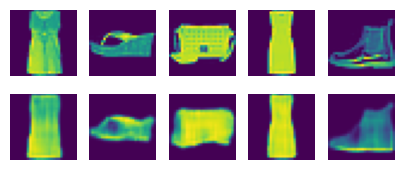

In [2]:
# 컴파일 및 학습을 하는 부분입니다.
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')
autoencoder.fit(X_train, X_train, epochs=50, batch_size=128, validation_data=(X_test, X_test))

# 학습된 결과를 출력하는 부분입니다.
random_test = np.random.randint(X_test.shape[0], size=5)  # 테스트할 이미지를 랜덤하게 불러옵니다.
ae_imgs = autoencoder.predict(X_test)                     # 앞서 만든 오토인코더 모델에 집어 넣습니다.

plt.figure(figsize=(7, 2))                         # 출력될 이미지의 크기를 정합니다.

for i, image_idx in enumerate(random_test):        # 랜덤하게 뽑은 이미지를 차례로 나열합니다.
   ax = plt.subplot(2, 7, i + 1)
   plt.imshow(X_test[image_idx].reshape(28, 28))   # 테스트할 이미지를 먼저 그대로 보여줍니다.
   ax.axis('off')
   ax = plt.subplot(2, 7, 7 + i +1)
   plt.imshow(ae_imgs[image_idx].reshape(28, 28))  # 오토인코딩 결과를 다음열에 출력합니다.
   ax.axis('off')
plt.show()

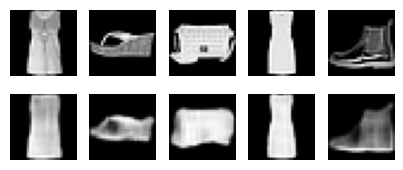

In [5]:
plt.figure(figsize=(7, 2))                         # 출력될 이미지의 크기를 정합니다.

for i, image_idx in enumerate(random_test):        # 랜덤하게 뽑은 이미지를 차례로 나열합니다.
   ax = plt.subplot(2, 7, i + 1)
   plt.imshow(X_test[image_idx].reshape(28, 28),cmap='gray')   # 테스트할 이미지를 먼저 그대로 보여줍니다.
   ax.axis('off')
   ax = plt.subplot(2, 7, 7 + i +1)
   plt.imshow(ae_imgs[image_idx].reshape(28, 28),cmap='gray')  # 오토인코딩 결과를 다음열에 출력합니다.
   ax.axis('off')
plt.show()